# Grandmaster EDA gốc

Notebook tái lập công thức **85% XGBoost offset + 10% LightGBM + 5% spline trên log-odds** cho Predicting Credit Card Fraud. Mã lựa chọn được lưu là **offset224_lgb10_spline05**. Điểm holdout đã lưu **ROC AUC 0,95122445**, **Average Precision 0,53823528**, **log loss 0,04383599**.

Các cell mặc định đọc đầu vào chính thức, tính lại chỉ số holdout, kiểm tra công thức khi có cache thành phần và xác minh CSV 299.984 dòng. Phần train lại nằm ở các cell có cờ cấu hình riêng.

[Báo cáo kỹ thuật](BAO_CAO_GRANDMASTER_EDA_GOC.md) · [Manifest](evaluation.json) · [CSV Grandmaster EDA gốc](submission_grandmaster_eda.csv)

## 1. Đường dẫn và chế độ chạy

Mở notebook trong repo **INT3405E_FD**. Đặt ba CSV chính thức dưới **data/**. Kernel dùng Python 3.11+ và numpy, pandas, scipy, scikit-learn, matplotlib. XGBoost, LightGBM, CatBoost và các phụ thuộc notebook Grandmaster cần cho phần huấn luyện đầy đủ. Có thể đặt biến môi trường **GRANDMASTER_REPO** nếu kernel được khởi động từ thư mục khác.

In [1]:
from hashlib import file_digest, sha256
import json
import os
from pathlib import Path
import shutil
import subprocess
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.special import expit
from sklearn.metrics import (
    average_precision_score, brier_score_loss, log_loss, roc_auc_score, roc_curve
)
from sklearn.model_selection import StratifiedShuffleSplit

def find_repo():
    configured = os.environ.get("GRANDMASTER_REPO")
    candidates = [Path(configured)] if configured else [Path.cwd(), *Path.cwd().parents]
    for parent in candidates:
        for root in (parent, parent / "INT3405E_FD"):
            if (root / "research/goal_0952/evaluation.json").is_file():
                return root.resolve()
    raise FileNotFoundError("Open this notebook within INT3405E_FD or set GRANDMASTER_REPO.")

def read_json(path):
    return json.loads(path.read_text(encoding="utf-8-sig"))

def digest(path):
    with path.open("rb") as stream:
        return file_digest(stream, "sha256").hexdigest()

def show(table):
    try:
        from IPython.display import display
    except ImportError:
        print(table.to_string(index=False))
    else:
        display(table)

REPO = find_repo()
RESEARCH = REPO / "research"
GOAL = RESEARCH / "goal_0952"
DATA = REPO / "data"
RECIPE = "offset224_lgb10_spline05"
CSV = GOAL / "submission_grandmaster_eda.csv"

BUILD_BASE_CACHES = False
FIT_THREE_COMPONENTS = False
WRITE_EXPORT_COPY = False
DEVICE = "cuda"

evaluation = read_json(GOAL / "evaluation.json")
assert evaluation["selected"] == RECIPE
print("Recipe:", RECIPE)
print("Official input directory found:", DATA.is_dir())

Recipe: offset224_lgb10_spline05
Official input directory found: True


## 2. Dữ liệu và tập kiểm chứng

Tập train có nhãn **is_fraud**. Các đặc trưng gồm 13 cột số, 5 cột nhóm và 6 cờ. **id** chỉ dùng để đối chiếu hàng. Dùng đúng phép chia phân tầng **85% phát triển, 15% holdout**, seed **4242**. Vòng CV phát triển có 10 fold seed 2026. Mọi thống kê có nhãn dùng tham chiếu phù hợp với vai trò fit và query.

In [2]:
for filename, expected in evaluation["input_sha256"].items():
    path = DATA / filename
    if not path.is_file():
        raise FileNotFoundError(f"Place the official {filename} under {DATA}")
    if digest(path) != expected:
        raise ValueError(f"Official input checksum mismatch: {filename}")

train = pd.read_csv(DATA / "train.csv")
test = pd.read_csv(DATA / "test.csv")
sample = pd.read_csv(DATA / "sample_submission.csv")
feature_names = [name for name in train if name not in {"id", "is_fraud"}]
assert len(feature_names) == 24 and list(test.columns) == ["id", *feature_names]
assert train["id"].is_unique and test["id"].is_unique and sample.id.equals(test.id)
assert set(train.is_fraud.unique()) == {0, 1}

fold_manifest = read_json(RESEARCH / "grandmaster_10fold_ablation/validation/metrics.json")
labels = train.is_fraud.to_numpy(dtype=np.uint8)
splitter = StratifiedShuffleSplit(
    n_splits=1, test_size=fold_manifest["holdout_fraction"], random_state=evaluation["holdout_seed"]
)
development, holdout = (np.sort(rows) for rows in next(splitter.split(labels, labels)))
holdout_ids = train.id.to_numpy()[holdout]
test_ids = test.id.to_numpy()
assert sha256(holdout_ids.tobytes()).hexdigest() == fold_manifest["holdout_ids_sha256"]
assert len(train) == 699_960 and len(test) == 299_984 and len(holdout) == evaluation["holdout_rows"]
show(pd.DataFrame([
    ("train", len(train), int(labels.sum()), float(labels.mean())),
    ("development", len(development), int(labels[development].sum()), float(labels[development].mean())),
    ("holdout", len(holdout), int(labels[holdout].sum()), float(labels[holdout].mean())),
    ("test", len(test), None, None),
], columns=["split", "rows", "fraud", "fraud_rate"]))
print("Missing cells:", int(train.isna().sum().sum()), "train /", int(test.isna().sum().sum()), "test")

      split   rows   fraud  fraud_rate
      train 699960 11689.0    0.016700
development 594966  9936.0    0.016700
    holdout 104994  1753.0    0.016696
       test 299984     NaN         NaN
Missing cells: 0 train / 0 test


## 3. Kiến trúc nền và ma trận D03

Grandmaster phân cấp có bảy đầu ra. Hai GLM logistic dùng biểu diễn spline và mã hóa, ba cây dốc học phần sai lệch quanh điểm GLM, một XGBoost riêng và một EBM. Tầng gộp dùng các độ lệch log-odds và trọng số không âm. Trong biến thể phân cấp, nhóm số tiền của Dense GLM dùng thống kê có điều chuẩn. Điểm log-odds từ tầng gộp đi vào XGBoost cuối qua **base_margin**.

Nhánh XGBoost: **54 raw + 13 TE + 6 phần cent + 36 khóa TE chữ số = 109**, cộng 12 tương tác EDA và 1 đặc trưng chữ số cuối của khoảng cách thành **122**. Nhánh LightGBM dùng **TE cho 24 trường**, tổng **120**. TE (target encoding) là tỷ lệ gian lận theo khóa có làm trơn về tỷ lệ chung.

In [3]:
sys.path.insert(0, str(REPO / "s6e11_gpu/plan_runs"))
from features import DIGIT_COLUMNS, DIGIT_NAMES, FeatureBuilder

# A small official-data subset measures widths using the actual feature builder.
train_example = train.iloc[development[:8_000]].reset_index(drop=True)
query_example = train.iloc[holdout[:16]].drop(columns="is_fraud").reset_index(drop=True)
builder = FeatureBuilder(train_example, query_example)
fit_example = np.arange(len(train_example))
query_positions = len(train_example) + np.arange(len(query_example))

xgb_groups = ("raw", "te13", "cents", "digits")
lgb_groups = ("raw", "te24", "cents", "digits")
train_xgb_demo, query_xgb_demo = builder.make(fit_example, (query_positions,), groups=xgb_groups)
train_lgb_demo, query_lgb_demo = builder.make(fit_example, (query_positions,), groups=lgb_groups)
assert train_xgb_demo.shape[1] == query_xgb_demo.shape[1] == 109
assert train_lgb_demo.shape[1] == query_lgb_demo.shape[1] == 120
show(pd.DataFrame([
    ("XGBoost D03", ", ".join(xgb_groups), 109),
    ("EDA residual features", "12 pairs + distance digit", 13),
    ("XGBoost offset input", "D03 + EDA", 122),
    ("LightGBM D03", ", ".join(lgb_groups), 120),
], columns=["matrix", "groups", "width"]))
print("Digit columns:", ", ".join(DIGIT_COLUMNS))
print("Digit key families:", ", ".join(DIGIT_NAMES))

               matrix                    groups  width
          XGBoost D03  raw, te13, cents, digits    109
EDA residual features 12 pairs + distance digit     13
 XGBoost offset input                 D03 + EDA    122
         LightGBM D03  raw, te24, cents, digits    120
Digit columns: amount_usd, hours_since_last_txn, distance_from_home_km, account_balance_usd, velocity_score, merchant_risk_score
Digit key families: cents, int, int10, tenths, lead1, lead2


## 4. Sàng lọc và mã hóa EDA

Từ 24 đặc trưng, sàng lọc **276 cặp** trên 594.966 giao dịch phát triển. Với xác suất nền **p**, mỗi ô tích lũy **G = Σ(y − p)**, **H = Σp(1 − p)** và số dòng **n**. Trừ hiệu ứng cộng của từng biến khỏi G, chia cho **H + 25** và chặn ở [−0,35, 0,35]. Đưa ô về 0 khi **H < 8** hoặc **n < 80**. Các cột số nhiều mức được chia theo phân vị của phần fit. Đặc trưng cuối áp dụng cùng nguyên tắc có điều chuẩn cho chữ số cuối của khoảng cách quy đổi theo cent.

Các dòng fit nhận 13 đặc trưng thông qua **5 fold con seed 62026**. Query dùng bảng ước lượng trên toàn bộ phần tham chiếu. Cột **cross_delta_logloss_x1m** dưới đây là điểm sàng lọc xấp xỉ tính chéo hai nửa phát triển.

In [4]:
discovery = read_json(GOAL / "residual_eda.json")
residual_metadata = read_json(GOAL / "residual_development_metrics.json")
assert discovery["discovery_rows"] == len(development)
assert len(discovery["pair_results"]) == 276
assert discovery["input_sha256"] == residual_metadata["input_sha256"] == evaluation["input_sha256"]
selected_pairs = [
    record for record in discovery["pair_results"]
    if (record["cross_delta_logloss_x1m"] or 0.0) > 2.0
][:12]
assert [[p["left"], p["right"]] for p in selected_pairs] == residual_metadata["selected_residual_pairs"]
show(pd.DataFrame(selected_pairs)[[
    "left", "right", "supported_cells", "spearman", "cross_delta_logloss_x1m"
]])

                left                     right  supported_cells  spearman  cross_delta_logloss_x1m
  txn_count_last_24h                 card_type               37  0.512565                11.420921
hours_since_last_txn       ip_country_mismatch               24  0.453913                 6.622986
     cvv_retry_count                 card_type               14  0.868132                 5.716339
         device_type           is_new_merchant               16  0.347059                 4.603157
 merchant_risk_score billing_shipping_mismatch               20  0.338346                 4.193955
      velocity_score billing_shipping_mismatch               20  0.443609                 3.197840
        customer_age billing_shipping_mismatch               21  0.284416                 3.124095
             channel billing_shipping_mismatch                9  0.983333                 2.673529
 account_balance_usd billing_shipping_mismatch               22  0.535855                 2.442634
         d

## 5. Ba mô hình và tùy chọn huấn luyện lại

| Nhánh | Cách train | Log-odds |
|---|---|---:|
| XGBoost offset | 224 vòng, max_depth 3, eta 0,025, min_child_weight 35, L2 40, L1 1,5. Dùng log-odds Grandmaster phân cấp làm base_margin. | 85% |
| LightGBM | 1.600 vòng, 4 lá, tốc độ 0,05 trên D03 TE24. | 10% |
| Spline logistic | Khối smooth theo từng biến, rồi thêm tương tác tensor đã sàng lọc. | 5% |

**Chạy dài theo nhu cầu.** Bật **BUILD_BASE_CACHES** để tạo dự đoán Grandmaster và Dense GLM phân cấp từ đầu. Bật **FIT_THREE_COMPONENTS** để chạy hai mode **development/full** của XGBoost và hai nhánh phụ. Các runner phát sinh checkpoint và số liệu trong thư mục chạy, có thể mất nhiều giờ. Nên huấn luyện trong bản checkout dành riêng cho thí nghiệm và dùng môi trường gốc ghi trong manifest. Khác phiên bản thư viện hoặc thiết bị có thể ảnh hưởng sai số số học. Cờ mặc định dùng các dự đoán đã xác minh ngay trong repo.

[Mã XGBoost](residual_models.py) · [Mã LightGBM](lightgbm_branch.py) · [Mã spline](spline_branch.py) · [Mã nền Grandmaster](../grandmaster_refit/run_refit.py)

In [5]:
def run_script(relative_path, *options):
    command = [sys.executable, "-B", str(RESEARCH / relative_path), *options]
    subprocess.run(command, cwd=REPO, check=True)

if BUILD_BASE_CACHES:
    run_script("grandmaster_refit/run_refit.py")
    run_script("grandmaster_10fold_ablation/run_ablation.py")
    run_script("grandmaster_10fold_ablation/export_hierarchical_submission.py")

if FIT_THREE_COMPONENTS:
    ablation = RESEARCH / "grandmaster_10fold_ablation"
    required_base = [
        ablation / "validation/holdout_predictions.csv",
        ablation / "submission_hierarchical_amount/submission.csv",
    ]
    for fold in range(1, 11):
        filename = f"fold_{fold:02}.npz"
        required_base.extend([
            ablation / "validation/artifacts" / filename,
            ablation / "submission_hierarchical_amount/artifacts" / f"dense_{filename}",
            RESEARCH / "grandmaster_refit/full/artifacts" / filename,
        ])
    missing = [str(path.relative_to(REPO)) for path in required_base if not path.is_file()]
    if missing:
        raise FileNotFoundError(f"{len(missing)} Grandmaster files missing. Run BUILD_BASE_CACHES first. Example: {missing[0]}")
    for mode in ("development", "full"):
        run_script("goal_0952/residual_models.py", mode, "--device", DEVICE)
    run_script("goal_0952/lightgbm_branch.py")
    run_script("goal_0952/spline_branch.py")
else:
    print("Archived output mode. Component training is disabled in section 1.")

Archived output mode. Component training is disabled in section 1.


## 6. Tái tạo công thức gộp và kiểm tra ID

Pipeline gộp các điểm log-odds rồi áp dụng sigmoid **p = 1 / (1 + exp(−z))**. Nếu sáu cache thành phần có sẵn, cell tính lại công thức từ logits. Có thể chỉ định thư mục cache bằng **GRANDMASTER_COMPONENTS**. Repo kèm bản phát hành cố định **selected_predictions.npz** để tính lại metric và xác minh CSV ngay cả trên checkout gọn.

In [6]:
component_keys = {
    "residual": ("ids", "offset_xgb_224"),
    "lightgbm": ("query_ids", "query_logits"),
    "spline": ("query_ids", "query_logits"),
}
component_weights = (0.85, 0.10, 0.05)
necessary = [
    f"{branch}_{mode}.npz"
    for mode in ("development", "full") for branch in component_keys
]
override = os.environ.get("GRANDMASTER_COMPONENTS")
if FIT_THREE_COMPONENTS:
    cache_paths = [GOAL]
elif override:
    cache_paths = [Path(override)]
else:
    cache_paths = [GOAL, REPO.parent / "goal_0952"]
components_dir = next(
    (path for path in cache_paths if all((path / name).is_file() for name in necessary)), None
)
if components_dir is None and override:
    raise FileNotFoundError("GRANDMASTER_COMPONENTS must contain all six component NPZ files.")

with np.load(GOAL / "selected_predictions.npz", allow_pickle=False) as saved:
    np.testing.assert_array_equal(saved["holdout_ids"], holdout_ids)
    np.testing.assert_array_equal(saved["test_ids"], test_ids)
    release_holdout = saved["holdout"].copy()
    release_test = saved["test"].copy()

def score_from_components(mode, expected_ids):
    margins = []
    for branch, (id_key, score_key) in component_keys.items():
        path = components_dir / f"{branch}_{mode}.npz"
        with np.load(path, allow_pickle=False) as cache:
            np.testing.assert_array_equal(cache[id_key], expected_ids)
            scores = cache[score_key].copy()
        if scores.shape != expected_ids.shape or not np.isfinite(scores).all():
            raise ValueError(f"Invalid logits: {path.name}")
        margins.append(scores)
    xgb, lgb, spline = margins
    w_xgb, w_lgb, w_spline = component_weights
    return expit(w_xgb * xgb + w_lgb * lgb + w_spline * spline)

if components_dir is not None:
    rebuilt_holdout = score_from_components("development", holdout_ids)
    rebuilt_test = score_from_components("full", test_ids)
    if not FIT_THREE_COMPONENTS:
        np.testing.assert_allclose(rebuilt_holdout, release_holdout, atol=1e-14, rtol=0)
        np.testing.assert_allclose(rebuilt_test, release_test, atol=1e-14, rtol=0)
        print("Replayed all three branches from cached logits and matched the frozen release.")
    else:
        print("New refit. Max absolute test difference:", np.max(np.abs(rebuilt_test - release_test)))
else:
    rebuilt_holdout, rebuilt_test = release_holdout, release_test
    print("Using the bundled release probabilities. Six branch caches are optional.")

Replayed all three branches from cached logits and matched the frozen release.


## 7. Kết quả holdout và đối chứng

Điểm **ROC AUC** đo khả năng xếp một ca gian lận trước ca hợp lệ. **Average Precision** quan tâm chất lượng truy tìm gian lận ở đầu danh sách. **Log loss** và **Brier** nhỏ hơn khi xác suất tốt hơn. Trong vòng gốc, holdout đã được dùng để so **27 công thức**, vì vậy các khoảng DeLong là khoảng ghép cặp theo dự đoán đã cố định. Việc chọn công thức trên cùng holdout làm mức tăng có thể lạc quan.

In [7]:
def compute_metrics(labels, p):
    return {
        "roc_auc": roc_auc_score(labels, p),
        "average_precision": average_precision_score(labels, p),
        "log_loss": log_loss(labels, p),
        "brier": brier_score_loss(labels, p),
    }

expected = evaluation["candidates"][RECIPE]
measured = compute_metrics(labels[holdout], release_holdout)
for metric in ("roc_auc", "average_precision", "log_loss"):
    np.testing.assert_allclose(measured[metric], expected[metric], rtol=0, atol=1e-12)
show(pd.DataFrame([measured], index=["Grandmaster EDA"]).round(9))
if FIT_THREE_COMPONENTS:
    show(pd.DataFrame([compute_metrics(labels[holdout], rebuilt_holdout)], index=["New refit"]).round(9))

selected_names = [
    "grandmaster_original", "grandmaster_hierarchical", "raw_offset_xgb_224",
    "offset_xgb_224", RECIPE,
]
ablation = pd.DataFrame(
    [dict(variant=name, **evaluation["candidates"][name]) for name in selected_names]
)
show(ablation[["variant", "roc_auc", "average_precision", "log_loss", "delta_auc"]].round(8))
print("Paired DeLong 95% interval:", (expected["ci95_low"], expected["ci95_high"]))
print("Remaining AUC to 0.952:", f"{evaluation['remaining_to_target']:.8f}")

 roc_auc  average_precision  log_loss    brier
0.951224           0.538235  0.043836 0.010632
                 variant  roc_auc  average_precision  log_loss  delta_auc
    grandmaster_original 0.950947           0.538149  0.043875  -0.000002
grandmaster_hierarchical 0.950949           0.538185  0.043874   0.000000
      raw_offset_xgb_224 0.951046           0.537738  0.043871   0.000097
          offset_xgb_224 0.951120           0.538037  0.043856   0.000171
offset224_lgb10_spline05 0.951224           0.538235  0.043836   0.000276
Paired DeLong 95% interval: (2.221332658130918e-05, 0.0005288265027826881)
Remaining AUC to 0.952: 0.00077555


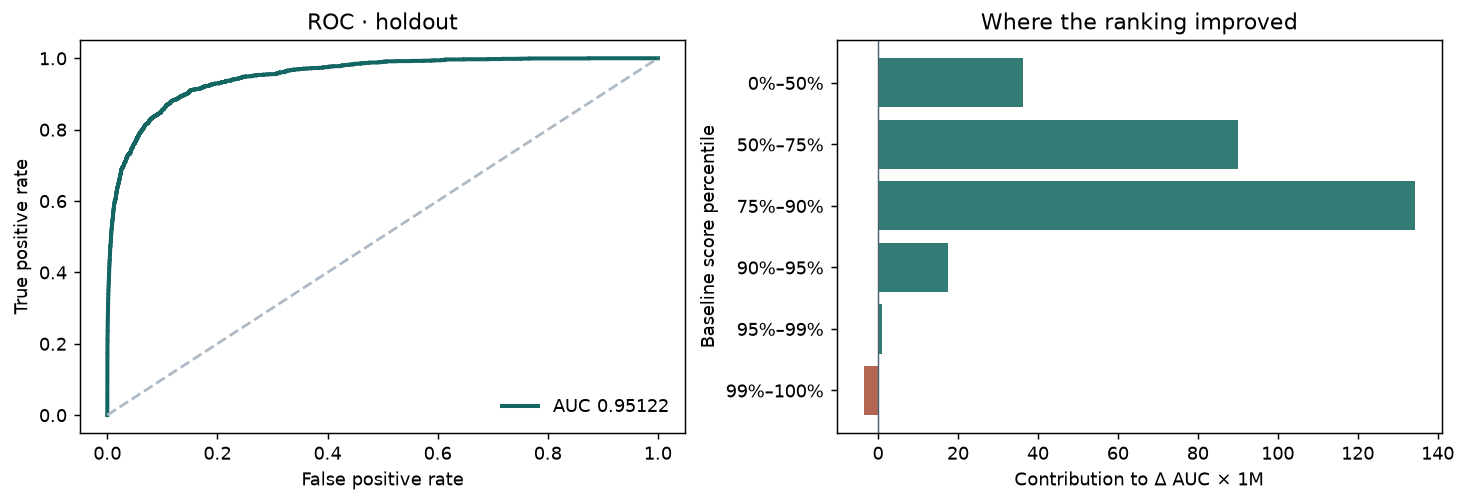

In [8]:
fpr, tpr, _ = roc_curve(labels[holdout], release_holdout)
bands = pd.DataFrame(evaluation["delta_auc_by_baseline_score_band"])
band_names = [f"{lo:.0%}–{hi:.0%}" for lo, hi in zip(bands.quantile_lower, bands.quantile_upper)]
np.testing.assert_allclose(bands.contribution_to_auc_delta.sum(), expected["delta_auc"], atol=1e-12)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.7), layout="constrained")
axes[0].plot(fpr, tpr, color="#136662", linewidth=2.2, label=f"AUC {measured['roc_auc']:.5f}")
axes[0].plot([0, 1], [0, 1], color="#adbac5", linestyle="--")
axes[0].set(xlabel="False positive rate", ylabel="True positive rate", title="ROC · holdout")
axes[0].legend(loc="lower right", frameon=False)
contributions = bands.contribution_to_auc_delta * 1e6
colors = np.where(contributions >= 0, "#337c75", "#b36651")
axes[1].barh(band_names, contributions, color=colors)
axes[1].axvline(0, color="#4c6374", linewidth=.8)
axes[1].set(xlabel="Contribution to Δ AUC × 1M", ylabel="Baseline score percentile",
            title="Where the ranking improved")
axes[1].invert_yaxis()
plt.show()

## 8. Submission gốc

Chạy xác minh đúng hai cột **id,is_fraud**, thứ tự theo **sample_submission.csv**, xác suất hữu hạn trong [0,1] và SHA-256 đúng manifest. Bật **WRITE_EXPORT_COPY** để tạo bản sao byte-exact trong **outputs/**. Điểm trong notebook là holdout local, mốc Public Leaderboard 0,95154 thuộc bản Grandmaster tham khảo của giai đoạn trước.

In [9]:
submission = pd.read_csv(CSV)
assert len(submission) == evaluation["submission_rows"] == len(sample)
assert list(submission.columns) == ["id", "is_fraud"]
assert submission.id.is_unique and submission.id.equals(test.id) and submission.id.equals(sample.id)
assert submission.is_fraud.between(0.0, 1.0).all()
np.testing.assert_allclose(submission.is_fraud, release_test, atol=1e-14, rtol=0)
assert digest(CSV) == evaluation["submission_sha256"]
print("Grandmaster EDA release rows:", f"{len(submission):,}")
print("SHA-256:", digest(CSV))

if WRITE_EXPORT_COPY:
    destination = REPO / "outputs/grandmaster_eda_notebook_copy.csv"
    destination.parent.mkdir(parents=True, exist_ok=True)
    with CSV.open("rb") as source, destination.open("xb") as output:
        shutil.copyfileobj(source, output)
    assert digest(destination) == evaluation["submission_sha256"]
    print("Exported:", destination.name)

Grandmaster EDA release rows: 299,984
SHA-256: 9aa21cdd324a0913c8f029dc4ebe1efcd3f51a8323c77ce93f13f283eba6f3d0


## Phạm vi tái lập

Notebook đọc các dự đoán đã lưu trong repo từ công thức gốc trên dữ liệu chính thức. Bản chạy mặc định đối chiếu toàn bộ 699.960 dòng train để xác định đúng holdout, toàn bộ 299.984 dòng test và các đầu ra lưu theo ID. Bảng so sánh dùng các trường của **evaluation.json**. Bảng tương tác dùng **residual_eda.json** và danh sách cặp trong **residual_development_metrics.json**. Chi tiết nguồn, công thức và giới hạn phép kiểm nằm trong [báo cáo kỹ thuật](BAO_CAO_GRANDMASTER_EDA_GOC.md).

- [Mã tách fold và kiểm dữ liệu](grandmaster_inputs.py)
- [Quy trình D03](../../s6e11_gpu/plan_runs/features.py)
- [Báo cáo EDA ban đầu](BAO_CAO_0952.md)
- [Kết quả từng công thức](evaluation.json)